# 5. Decay of Search Interest in 2011

This notebook draws Figure 2d and computes how fast Search Interest fell after the accident.
It uses the weekly 2011 Search Interest (`data/search_interest/weekly_2011.csv`), in which each prefecture is
normalized to its own maximum of 100.
The prefectures are grouped by distance from Fukushima: up to 250 km, 250 to 750 km, and over 750 km.
Fukushima itself is not in any group and is drawn as a black line for reference.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from japanmap import picture

DATA = Path("../data")
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "figure.dpi": 150,
})

prefectures = pd.read_csv(DATA / "prefectures.csv")

In [2]:
weekly = pd.read_csv(DATA / "search_interest" / "weekly_2011.csv", parse_dates=["week"], index_col="week")
weekly = weekly.replace("<1", 1).astype(float)   # "<1" (below 1) is counted as 1
assert list(weekly.columns) == prefectures["prefecture"].tolist()

GROUPS = ["≤250 km", "250–750 km", "≥750 km"]
COLOR = {"≤250 km": "#1f77b4", "250–750 km": "#ff7f0e", "≥750 km": "#2ca02c"}
group_of = {p: GROUPS[0] if km <= 250 else GROUPS[1] if km <= 750 else GROUPS[2]
            for p, km in zip(prefectures["prefecture"], prefectures["distance_km"]) if p != "Fukushima"}
members = {g: [p for p, gp in group_of.items() if gp == g] for g in GROUPS}
print("Prefectures in each distance group (Fukushima is not in any group):")
for g in GROUPS:
    print(f"  {g} from Fukushima, {len(members[g])} prefectures: {', '.join(members[g])}")

mean = {g: weekly[members[g]].mean(axis=1) for g in GROUPS}
sd = {g: weekly[members[g]].std(axis=1) for g in GROUPS}
fukushima = weekly["Fukushima"]

Prefectures in each distance group (Fukushima is not in any group):
  ≤250 km from Fukushima, 12 prefectures: Iwate, Miyagi, Akita, Yamagata, Ibaraki, Tochigi, Gunma, Saitama, Chiba, Tokyo, Niigata, Nagano
  250–750 km from Fukushima, 22 prefectures: Hokkaido, Aomori, Kanagawa, Toyama, Ishikawa, Fukui, Yamanashi, Gifu, Shizuoka, Aichi, Mie, Shiga, Kyoto, Osaka, Hyogo, Nara, Wakayama, Tottori, Shimane, Okayama, Tokushima, Kagawa
  ≥750 km from Fukushima, 12 prefectures: Hiroshima, Yamaguchi, Ehime, Kochi, Fukuoka, Saga, Nagasaki, Kumamoto, Oita, Miyazaki, Kagoshima, Okinawa


## Figure 2d

Colored lines are the mean Search Interest of each group, shaded bands are ±1 standard deviation, dashed lines
are each group's mean in January and February 2011, before the accident, and the black line is Fukushima, for
reference.
The insets show where the prefectures of each group are.

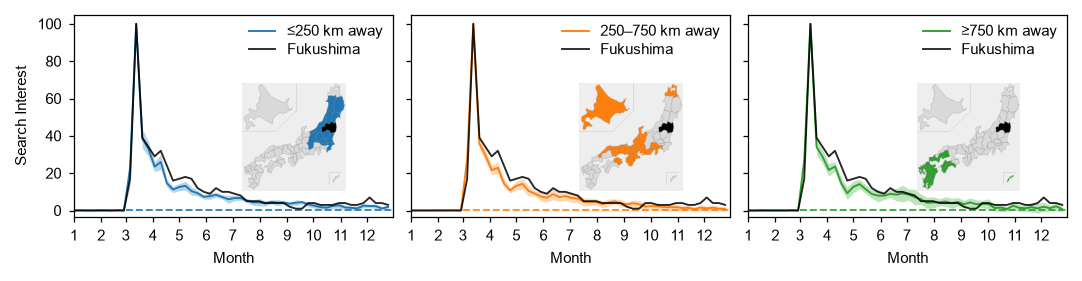

In [3]:
code_of = dict(zip(prefectures["prefecture"], prefectures["code"]))

def group_picture(g):
    colors = {code: "#d9d9d9" for code in code_of.values()}
    colors.update({code_of[p]: COLOR[g] for p in members[g]})
    colors[code_of["Fukushima"]] = "#000000"
    return picture(pd.Series(colors))

fig, axes = plt.subplots(1, 3, figsize=(7.1, 1.76), sharey=True, layout="constrained")
months = pd.date_range("2011-01-01", "2011-12-31", freq="MS")
bottom = min(0, min((mean[g] - sd[g]).min() for g in GROUPS)) - 2
for i, (ax, g) in enumerate(zip(axes, GROUPS)):
    ax.plot(mean[g].index, mean[g], color=COLOR[g], linewidth=0.9, label=f"{g} away")
    ax.fill_between(mean[g].index, mean[g] - sd[g], mean[g] + sd[g], color=COLOR[g], alpha=0.3, linewidth=0)
    baseline = mean[g].loc["2011-01":"2011-02"].mean()
    ax.plot(pd.date_range("2011-03-01", "2012-01-01", freq="MS"), [baseline] * 11, color=COLOR[g], linestyle="--",
            linewidth=0.9, alpha=0.9)
    ax.plot(fukushima.index, fukushima, color="black", linewidth=0.9, alpha=0.85, label="Fukushima")
    ax.set_xlim(pd.Timestamp("2011-01-01"), pd.Timestamp("2011-12-31"))
    ax.set_xticks(months, [str(m.month) for m in months])
    ax.set_xlabel("Month")
    ax.set_ylim(bottom, 105)
    if i == 0:
        ax.set_ylabel("Search Interest")
    ax.legend(loc="upper right", frameon=False, handlelength=1.8, labelspacing=0.3, borderaxespad=0.3)
    inset = ax.inset_axes([0.40, 0.13, 0.58, 0.53])
    inset.imshow(group_picture(g))
    inset.axis("off")
plt.show()

In [4]:
def decay(series):
    start = series.idxmax()                      # each week is labeled by its first day (a Sunday)
    end = start + pd.Timedelta(days=6)
    after = series.loc[start:]
    row = {"peak week": f"{start:%d %b} – {end:%d %b %Y}"}
    for share in (0.5, 0.2):
        below = after[after < share * series.max()].index.min()
        row[f"weeks to below {int(share * 100)}%"] = (below - start).days // 7
    return row

pd.DataFrame({**{g: decay(mean[g]) for g in GROUPS}, "Fukushima": decay(fukushima)}).T

,peak week,weeks to below 50%,weeks to below 20%
≤250 km,13 Mar – 19 Mar 2011,1,5
250–750 km,13 Mar – 19 Mar 2011,1,5
≥750 km,13 Mar – 19 Mar 2011,1,5
Fukushima,13 Mar – 19 Mar 2011,1,6


For each group's mean and for Fukushima, the table gives the week in which Search Interest peaked (reached its
maximum of 100) and how many weeks it took to fall below 50% and below 20% of the peak.